# MLP: predicción de incumplimiento de pagos

## Objetivo
Implementar y evaluar una red neuronal completamente conectada
para predecir el incumplimiento de pago del siguiente mes.

## Datos
Se utiliza Default of Credit Card Clients de UCI:
30,000 clientes de Taiwán y 23 variables predictoras.

Fuente:
https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

## Metodología
Se realiza exploración de datos, división por perfiles para evitar
coincidencias entre particiones, preprocesamiento ajustado solo
con entrenamiento, comparación con regresión logística y selección
del umbral usando validación. La evaluación final utiliza prueba.

El notebook incluye curvas de aprendizaje, métricas, matriz de
confusión, ejemplos de predicciones y guardado de resultados.

## Ejecución
Ejecutar todas las celdas en orden en Google Colab. CPU es suficiente.
La descarga inicial requiere conexión a internet. Los archivos
generados se guardan en /content/resultados_mlp, una ubicación
temporal que no se incluye automáticamente al guardar el notebook.

## Alcance
Los datos son históricos y corresponden a una población específica.
El proyecto es académico y no demuestra aptitud para decisiones
crediticias actuales.

In [1]:
%pip -q install xlrd==2.0.1

In [2]:
import io
import zipfile
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)

pandas: 2.2.3
NumPy: 2.4.6


## 1. Descargar desde UCI y cargar el Excel original

In [3]:
URL = 'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip'
with urlopen(URL, timeout=60) as response:
    archive_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    names = [n for n in archive.namelist() if n.lower().endswith('.xls')]
    assert len(names) == 1, names
    df = pd.read_excel(io.BytesIO(archive.read(names[0])), header=1, engine='xlrd')
print('Filas y columnas:', df.shape)
display(df.head())

Filas y columnas: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Entender las variables
- ID: identificador que excluiremos del modelo.
- LIMIT_BAL: límite de crédito en dólares taiwaneses; AGE: edad.
- SEX, EDUCATION, MARRIAGE: categorías codificadas numéricamente.
- PAY_0, PAY_2 a PAY_6: estados de pago previos (no existe PAY_1 en la nomenclatura original).
- BILL_AMT1 a BILL_AMT6: importes de estados de cuenta.
- PAY_AMT1 a PAY_AMT6: importes pagados.
- default payment next month: objetivo, 1 = incumplió; 0 = no incumplió.

Los códigos categóricos y los importes negativos requieren interpretación antes de tratarlos como errores.

In [4]:
TARGET = 'default payment next month'
assert TARGET in df.columns, df.columns.tolist()
assert df[TARGET].notna().all()
assert set(df[TARGET].unique()) == {0, 1}
print(df.columns.tolist())
df.info()
display(df.describe().T)

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null 

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


## 3. Revisar calidad sin eliminar ni transformar registros

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
print('Total de celdas faltantes:', int(missing.sum()))
display(missing[missing > 0].to_frame('faltantes'))
print('Filas idénticas con ID:', int(df.duplicated().sum()))
print('ID repetidos:', int(df['ID'].duplicated().sum()))
print('Filas repetidas sin ID, incluyendo etiqueta:', int(df.drop(columns='ID').duplicated().sum()))
for col in ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']:
    print(f'\n{col}:')
    print(df[col].value_counts(dropna=False).sort_index().to_string())

Total de celdas faltantes: 0


,faltantes


Filas idénticas con ID: 0
ID repetidos: 0
Filas repetidas sin ID, incluyendo etiqueta: 35

SEX:
SEX
1    11888
2    18112

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323

PAY_0:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19

PAY_2:
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1

PAY_3:
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3

PAY_4:
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2

PAY_5:
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8       

## 4. Distribución de clases
Calcularemos la accuracy de predecir siempre la clase mayoritaria. Es una referencia descriptiva del dataset completo, **no un resultado en test**. Puede ser alta aunque no se detecten incumplimientos.

,clientes,porcentaje
default payment next month,,
0,23364,77.88
1,6636,22.12


Accuracy descriptiva de clase mayoritaria: 77.88%


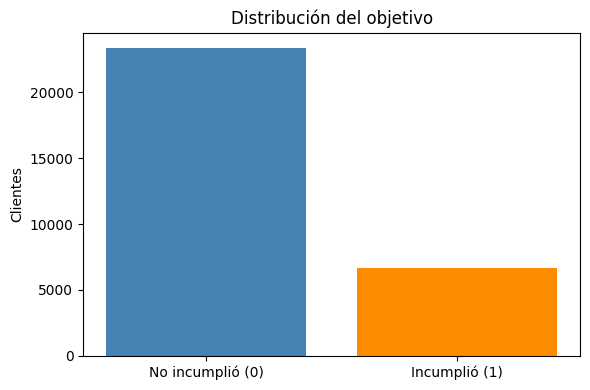

In [6]:
counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
summary = pd.DataFrame({'clientes': counts, 'porcentaje': 100 * counts / counts.sum()})
display(summary.round(2))
print(f'Accuracy descriptiva de clase mayoritaria: {counts.max() / counts.sum():.2%}')
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['No incumplió (0)', 'Incumplió (1)'], counts.values, color=['steelblue', 'darkorange'])
ax.set(ylabel='Clientes', title='Distribución del objetivo')
plt.tight_layout()
plt.show()

## 5. Observar escalas y distribuciones numéricas

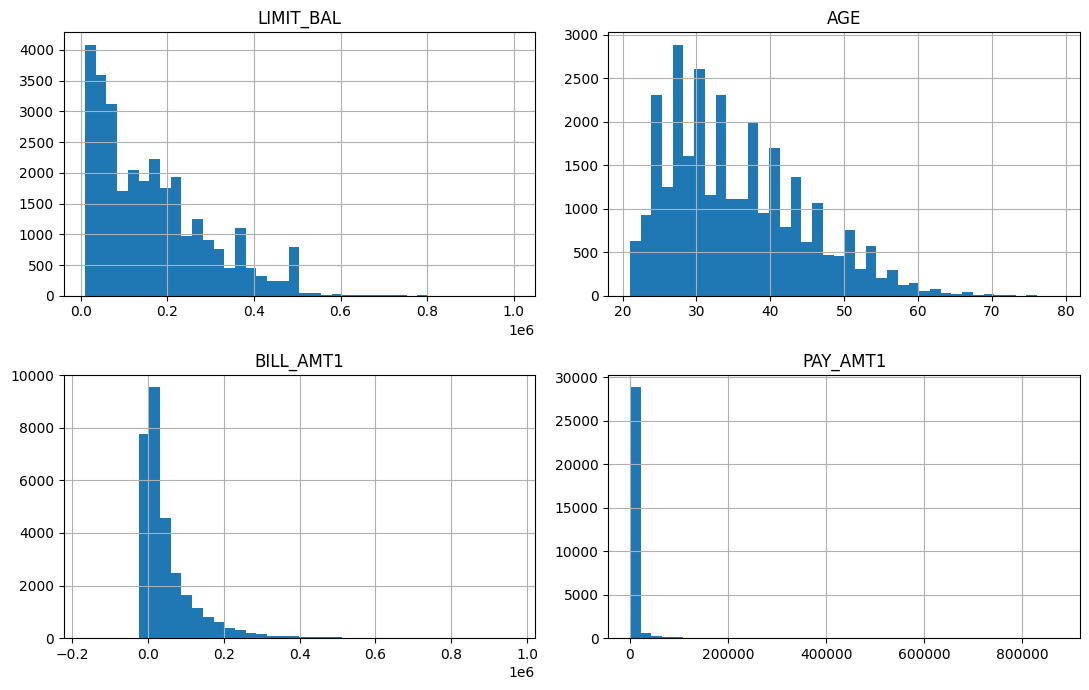

In [7]:
df[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].hist(bins=40, figsize=(11, 7))
plt.tight_layout()
plt.show()

## 6. Observaciones de la exploración

1. **Tamaño:** se cargaron 30,000 filas y 25 columnas:
   23 variables predictoras, un identificador y el objetivo.

2. **Incumplimiento:** 6,636 clientes incumplieron, equivalentes
   al 22.12 % del dataset.

3. **Clase mayoritaria:** predecir siempre “no incumplirá” obtiene
   77.88 % de accuracy, pero no identifica ningún incumplimiento.
   Por eso también evaluaremos precision, recall y F1
   de la clase positiva.

4. **Calidad:** no se encontraron valores faltantes ni ID repetidos.
   Se encontraron 35 filas repetidas al excluir ID e incluir
   la etiqueta. Revisaremos también los perfiles definidos
   únicamente por las variables predictoras.

5. **Códigos por revisar:** EDUCATION contiene 0, 5 y 6;
   MARRIAGE contiene 0; los estados de pago incluyen -2 y 0,
   cuya interpretación no queda clara en la descripción consultada.
   Documentaremos su tratamiento sin asumir que son errores.

6. **Escalas:** las variables numéricas tienen escalas diferentes
   y valores extremos. Ajustaremos el escalado solo con los
   datos de entrenamiento.

In [8]:
# Buscamos clientes con exactamente las mismas variables predictoras.
# Excluimos tanto el identificador como la respuesta.
feature_cols = df.columns.drop(["ID", TARGET]).tolist()

profile_summary = (
    df.groupby(feature_cols, dropna=False)[TARGET]
    .agg(registros="size", etiquetas_distintas="nunique")
)

repeated_profiles = profile_summary.query("registros > 1")

print("Perfiles que aparecen más de una vez:", len(repeated_profiles))
print("Clientes en esos perfiles:", int(repeated_profiles["registros"].sum()))
print(
    "Perfiles iguales con etiquetas diferentes:",
    int((repeated_profiles["etiquetas_distintas"] > 1).sum())
)

Perfiles que aparecen más de una vez: 52
Clientes en esos perfiles: 108
Perfiles iguales con etiquetas diferentes: 21


## 7. División de datos

Se identificaron 52 perfiles repetidos que abarcan 108 clientes.
De esos perfiles, 21 presentan etiquetas diferentes.

Se conservarán los registros, pues la coincidencia de características
no demuestra que sean la misma persona. Para evitar que perfiles
idénticos aparezcan en entrenamiento y evaluación, se dividirán
los datos por grupos de características iguales.

Usaremos aproximadamente 70 % para entrenamiento, 10 % para
validación y 20 % para prueba, procurando conservar la proporción
de incumplimiento.

Validación servirá para elegir configuraciones. El conjunto de
prueba se reservará para evaluar el modelo final.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

X = df[feature_cols].copy()
y = df[TARGET].copy()

# Cada combinación exacta de predictores recibe un grupo.
# No usamos ID ni la etiqueta para definir los grupos.
groups = pd.Series(
    pd.factorize(pd.MultiIndex.from_frame(X))[0],
    index=df.index,
    name="perfil"
)

splitter = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=SEED
)

fold = np.full(len(df), -1, dtype=int)

for fold_number, (_, held_out_idx) in enumerate(
    splitter.split(X, y, groups=groups)
):
    fold[held_out_idx] = fold_number

train_idx = np.flatnonzero(fold < 7)
val_idx = np.flatnonzero(fold == 7)
test_idx = np.flatnonzero(fold >= 8)

X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
X_val, y_val = X.iloc[val_idx].copy(), y.iloc[val_idx].copy()
X_test, y_test = X.iloc[test_idx].copy(), y.iloc[test_idx].copy()

# Verificamos cobertura y ausencia de perfiles compartidos.
assert (fold >= 0).all()
assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)

train_groups = set(groups.iloc[train_idx])
val_groups = set(groups.iloc[val_idx])
test_groups = set(groups.iloc[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

partitions = {
    "Entrenamiento": y_train,
    "Validación": y_val,
    "Prueba": y_test,
}

display(pd.DataFrame([
    {
        "partición": name,
        "clientes": len(labels),
        "% del total": 100 * len(labels) / len(df),
        "% incumplimiento": 100 * labels.mean(),
    }
    for name, labels in partitions.items()
]).round(2))

print("Verificación correcta: no hay perfiles compartidos entre particiones.")

,partición,clientes,% del total,% incumplimiento
0,Entrenamiento,20995,69.98,22.16
1,Validación,3001,10.00,23.13
2,Prueba,6004,20.01,21.47


Verificación correcta: no hay perfiles compartidos entre particiones.


## 8. Preprocesamiento

Se excluye ID porque identifica al cliente y no representa
una característica útil para generalizar.

SEX, EDUCATION, MARRIAGE y los estados mensuales de pago se
tratarán como variables categóricas mediante one-hot encoding.
Se conservarán los códigos originales, incluidos aquellos cuya
interpretación es incompleta, sin asignarles significados
no confirmados. Para los estados de pago, esta representación
permite aprender efectos separados de cada código.

Las variables numéricas se estandarizarán con StandardScaler.
Se conservarán los importes negativos y extremos en esta primera
versión, pues no se ha demostrado que sean errores.

El preprocesador aprenderá sus parámetros únicamente con
entrenamiento. Validación se transformará con esos mismos
parámetros. El conjunto de prueba permanecerá reservado.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
]

numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            ),
            categorical_cols
        ),
        ("numeric", StandardScaler(), numeric_cols)
    ],
    remainder="drop"
)

# Solo entrenamiento determina categorías, medias y escalas.
X_train_prepared = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_prepared = preprocessor.transform(X_val).astype(np.float32)

assert "ID" not in X_train.columns
assert TARGET not in X_train.columns
assert X_train_prepared.shape[1] == X_val_prepared.shape[1]
assert np.isfinite(X_train_prepared).all()
assert np.isfinite(X_val_prepared).all()

print("Entrenamiento preparado:", X_train_prepared.shape)
print("Validación preparada:", X_val_prepared.shape)
print("Variables numéricas:", len(numeric_cols))
print("Variables categóricas originales:", len(categorical_cols))

# Detectamos categorías de validación ausentes en entrenamiento.
for col in categorical_cols:
    unseen = sorted(set(X_val[col]) - set(X_train[col]))
    if unseen:
        print(f"Categorías nuevas en validación para {col}: {unseen}")

print("Preprocesamiento completado sin valores no finitos.")

Entrenamiento preparado: (20995, 91)
Validación preparada: (3001, 91)
Variables numéricas: 14
Variables categóricas originales: 9
Preprocesamiento completado sin valores no finitos.


## 9. Modelo de referencia: regresión logística

Se entrenará una regresión logística utilizando las mismas
variables preparadas que recibirá el MLP.

Esta primera referencia no utiliza ponderación de clases
y emplea un umbral de clasificación de 0.5.

Se evaluará únicamente en validación mediante accuracy,
precision, recall, F1, ROC-AUC y average precision.
Precision, recall y F1 se calcularán para incumplimiento
(clase positiva = 1).

El conjunto de prueba permanece reservado.

,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Regresión logística — validación,0.8164,0.7134,0.3444,0.4645,0.7761,0.5684


Accuracy de predecir siempre la clase mayoritaria: 76.87%


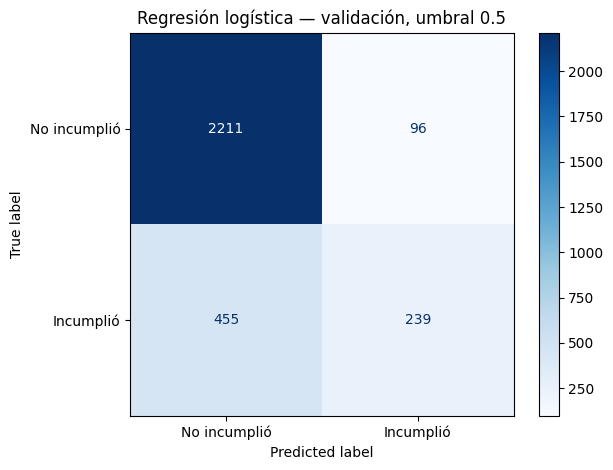

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

baseline = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

baseline.fit(X_train_prepared, y_train)

# Probabilidad de incumplimiento y decisión con umbral fijo.
positive_col = list(baseline.classes_).index(1)
val_prob_baseline = baseline.predict_proba(
    X_val_prepared
)[:, positive_col]

val_pred_baseline = (val_prob_baseline >= 0.5).astype(int)

baseline_results = {
    "Accuracy": accuracy_score(y_val, val_pred_baseline),
    "Precision": precision_score(
        y_val, val_pred_baseline, zero_division=0
    ),
    "Recall": recall_score(
        y_val, val_pred_baseline, zero_division=0
    ),
    "F1": f1_score(y_val, val_pred_baseline, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, val_prob_baseline),
    "Average precision": average_precision_score(
        y_val, val_prob_baseline
    )
}

display(
    pd.DataFrame(
        baseline_results,
        index=["Regresión logística — validación"]
    ).round(4)
)

# Referencia constante calculada en la misma validación.
majority_class = int(y_train.mode().iloc[0])
constant_predictions = np.full(len(y_val), majority_class)

print(
    "Accuracy de predecir siempre la clase mayoritaria:",
    f"{accuracy_score(y_val, constant_predictions):.2%}"
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred_baseline,
    labels=[0, 1],
    display_labels=["No incumplió", "Incumplió"],
    cmap="Blues",
    values_format="d"
)
plt.title("Regresión logística — validación, umbral 0.5")
plt.tight_layout()
plt.show()

### Resultados del modelo de referencia

La regresión logística obtuvo en validación una accuracy de
81.64 %, frente a 76.87 % de la predicción constante mayoritaria.

Para incumplimiento obtuvo precision de 71.34 %, recall de
34.44 % y F1 de 0.4645. Detectó 239 incumplimientos, pero
no detectó otros 455.

El modelo presenta capacidad predictiva, aunque su accuracy
no refleja por sí sola la dificultad para detectar la clase
positiva. Estos resultados corresponden al umbral de 0.5.

Servirá como referencia para comparar el MLP utilizando
la misma partición y el mismo preprocesamiento.

## 10. MLP inicial

Se utilizarán dos capas ocultas de 64 y 32 neuronas con
activación ReLU, y dropout de 0.2 después de cada una para
reducir el sobreajuste.

La salida tendrá una neurona sigmoid para estimar la
probabilidad de incumplimiento. Se utilizarán binary
crossentropy y el optimizador Adam con learning rate 0.001.

El entrenamiento tendrá un máximo de 50 épocas y lotes
de 128 clientes. Early stopping detendrá el entrenamiento
si la pérdida de validación no mejora durante 7 épocas
y restaurará los mejores pesos.

Esta primera versión no utilizará ponderación de clases.
El conjunto de prueba permanece reservado.

In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

mlp = keras.Sequential([
    keras.Input(shape=(X_train_prepared.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="roc_auc")
    ]
)

mlp.summary()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = mlp.fit(
    X_train_prepared,
    y_train.to_numpy(dtype=np.float32),
    validation_data=(
        X_val_prepared,
        y_val.to_numpy(dtype=np.float32)
    ),
    epochs=50,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=2
)

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print("Épocas ejecutadas:", len(history.history["loss"]))
print("Mejor época según val_loss:", best_epoch)

TensorFlow: 2.21.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,001 (31.25 KB)

 Trainable params: 8,001 (31.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
165/165 - 2s - 14ms/step - accuracy: 0.7896 - loss: 0.4867 - roc_auc: 0.6967 - val_accuracy: 0.7991 - val_loss: 0.4517 - val_roc_auc: 0.7706
Epoch 2/50
165/165 - 1s - 4ms/step - accuracy: 0.8118 - loss: 0.4512 - roc_auc: 0.7489 - val_accuracy: 0.8097 - val_loss: 0.4419 - val_roc_auc: 0.7793
Epoch 3/50
165/165 - 1s - 4ms/step - accuracy: 0.8179 - loss: 0.4428 - roc_auc: 0.7577 - val_accuracy: 0.8121 - val_loss: 0.4385 - val_roc_auc: 0.7828
Epoch 4/50
165/165 - 1s - 4ms/step - accuracy: 0.8186 - loss: 0.4384 - roc_auc: 0.7663 - val_accuracy: 0.8134 - val_loss: 0.4358 - val_roc_auc: 0.7843
Epoch 5/50
165/165 - 1s - 4ms/step - accuracy: 0.8206 - loss: 0.4359 - roc_auc: 0.7670 - val_accuracy: 0.8161 - val_loss: 0.4349 - val_roc_auc: 0.7839
Epoch 6/50
165/165 - 1s - 4ms/step - accuracy: 0.8203 - loss: 0.4343 - roc_auc: 0.7710 - val_accuracy: 0.8164 - val_loss: 0.4341 - val_roc_auc: 0.7868
Epoch 7/50
165/165 - 1s - 4ms/step - accuracy: 0.8213 - loss: 0.4331 - roc_auc: 0.7727 - val_

Resultados en validación — umbral 0.5


,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Regresión logística,0.8164,0.7134,0.3444,0.4645,0.7761,0.5684
MLP inicial,0.8184,0.7159,0.3559,0.4755,0.7885,0.5866


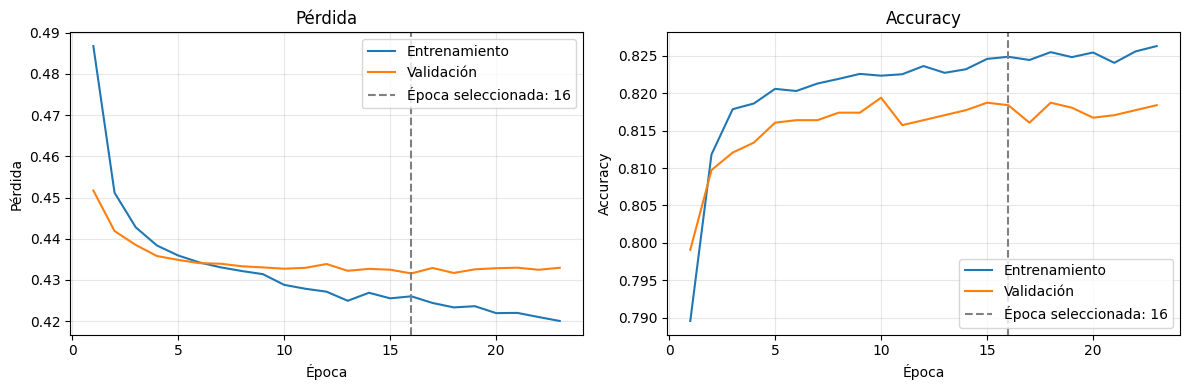

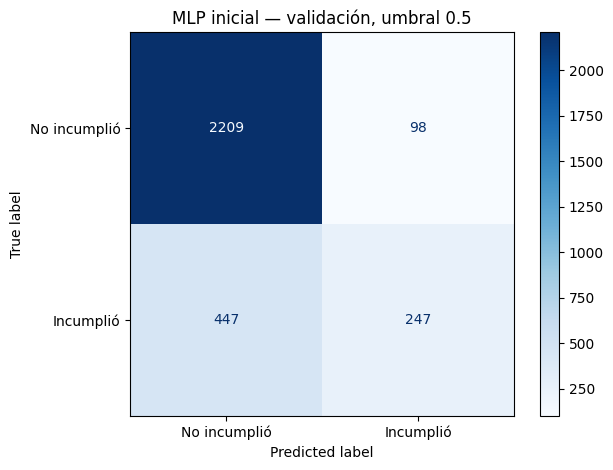

In [13]:
# Evaluar los pesos restaurados por early stopping.
val_prob_mlp = mlp.predict(X_val_prepared, verbose=0).ravel()
val_pred_mlp = (val_prob_mlp >= 0.5).astype(int)

mlp_results = {
    "Accuracy": accuracy_score(y_val, val_pred_mlp),
    "Precision": precision_score(
        y_val, val_pred_mlp, zero_division=0
    ),
    "Recall": recall_score(
        y_val, val_pred_mlp, zero_division=0
    ),
    "F1": f1_score(y_val, val_pred_mlp, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, val_prob_mlp),
    "Average precision": average_precision_score(
        y_val, val_prob_mlp
    )
}

comparison = pd.DataFrame(
    [baseline_results, mlp_results],
    index=["Regresión logística", "MLP inicial"]
)

print("Resultados en validación — umbral 0.5")
display(comparison.round(4))

# Curvas de aprendizaje.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric, title in [
    (axes[0], "loss", "Pérdida"),
    (axes[1], "accuracy", "Accuracy")
]:
    ax.plot(epochs, history.history[metric], label="Entrenamiento")
    ax.plot(
        epochs,
        history.history[f"val_{metric}"],
        label="Validación"
    )
    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label=f"Época seleccionada: {best_epoch}"
    )
    ax.set(title=title, xlabel="Época", ylabel=title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred_mlp,
    labels=[0, 1],
    display_labels=["No incumplió", "Incumplió"],
    cmap="Blues",
    values_format="d"
)
plt.title("MLP inicial — validación, umbral 0.5")
plt.tight_layout()
plt.show()

## 11. Experimento: selección del umbral

Se compararán umbrales entre 0.10 y 0.90, en incrementos de 0.01,
para ambos modelos. Se seleccionará el umbral que maximice F1
de incumplimiento en validación. En caso de empate, se elegirá
el menor umbral.

Este experimento modifica la regla de clasificación, no los
pesos de los modelos. Las métricas obtenidas son resultados
de selección en validación; la evaluación final se realizará
posteriormente sobre prueba, con el umbral ya fijado.

,Umbral,Accuracy,Precision,Recall,F1
Modelo,,,,,
MLP inicial,0.26,0.7774,0.5160,0.6023,0.5559
Regresión logística,0.22,0.7734,0.5087,0.5879,0.5455


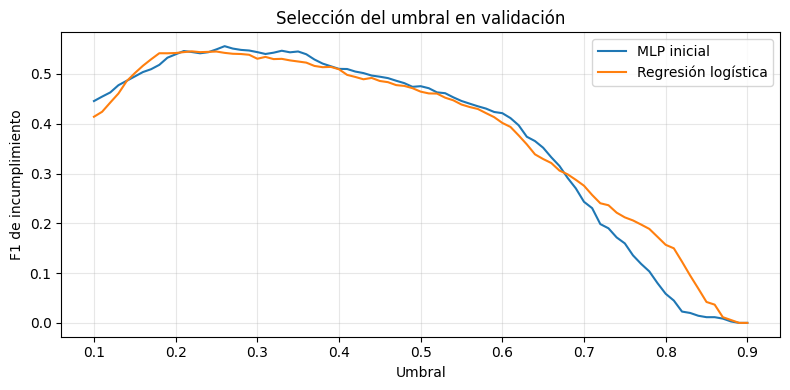

In [14]:
threshold_rows = []

for name, probabilities in [
    ("Regresión logística", val_prob_baseline),
    ("MLP inicial", val_prob_mlp)
]:
    for threshold in np.round(np.linspace(0.10, 0.90, 81), 2):
        predictions = (probabilities >= threshold).astype(int)

        threshold_rows.append({
            "Modelo": name,
            "Umbral": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(y_val, predictions, zero_division=0)
        })

threshold_results = pd.DataFrame(threshold_rows)

best_thresholds = (
    threshold_results
    .sort_values(
        ["Modelo", "F1", "Umbral"],
        ascending=[True, False, True]
    )
    .drop_duplicates("Modelo")
    .set_index("Modelo")
)

display(best_thresholds.round(4))

fig, ax = plt.subplots(figsize=(8, 4))

for name, results in threshold_results.groupby("Modelo"):
    ax.plot(results["Umbral"], results["F1"], label=name)

ax.set(
    xlabel="Umbral",
    ylabel="F1 de incumplimiento",
    title="Selección del umbral en validación"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

selected_mlp_threshold = float(
    best_thresholds.loc["MLP inicial", "Umbral"]
)

## 12. Evaluación final en prueba

En validación, el MLP con umbral 0.26 obtuvo F1 de 0.5559,
precision de 51.60 % y recall de 60.23 %. Se selecciona esta
configuración por su F1, reconociendo el aumento de falsas alarmas.

La regresión logística se evaluará con su umbral seleccionado
en validación: 0.22.

Se mantienen los pesos restaurados por early stopping y el
preprocesador ajustado únicamente con entrenamiento.
Los resultados de prueba no se utilizarán para ajustar modelos
ni umbrales.

,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Modelo,,,,,,,
Regresión logística,0.22,0.7753,0.4807,0.5811,0.5262,0.7713,0.5393
MLP inicial,0.26,0.7798,0.4896,0.6005,0.5394,0.7830,0.5563


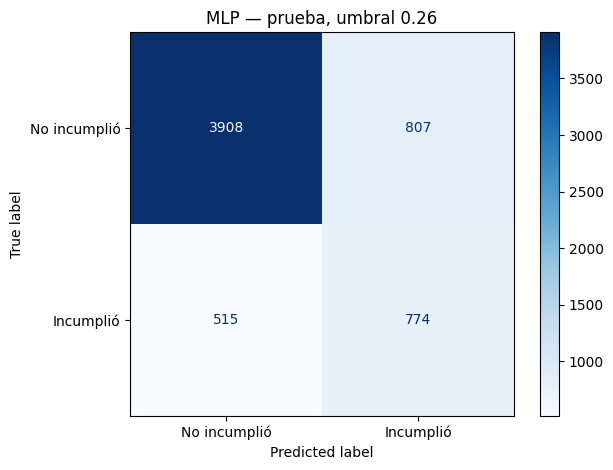

In [15]:
# Transformar prueba sin volver a ajustar el preprocesador.
X_test_prepared = preprocessor.transform(X_test).astype(np.float32)

assert np.isfinite(X_test_prepared).all()
assert X_test_prepared.shape[1] == X_train_prepared.shape[1]

test_prob_mlp = mlp.predict(
    X_test_prepared, verbose=0
).ravel()

test_prob_baseline = baseline.predict_proba(
    X_test_prepared
)[:, positive_col]

final_thresholds = {
    name: float(best_thresholds.loc[name, "Umbral"])
    for name in ["Regresión logística", "MLP inicial"]
}

test_rows = []

for name, probabilities in [
    ("Regresión logística", test_prob_baseline),
    ("MLP inicial", test_prob_mlp)
]:
    threshold = final_thresholds[name]
    predictions = (probabilities >= threshold).astype(int)

    test_rows.append({
        "Modelo": name,
        "Umbral": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(
            y_test, probabilities
        )
    })

test_results = pd.DataFrame(test_rows).set_index("Modelo")
display(test_results.round(4))

test_pred_mlp = (
    test_prob_mlp >= final_thresholds["MLP inicial"]
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred_mlp,
    labels=[0, 1],
    display_labels=["No incumplió", "Incumplió"],
    cmap="Blues",
    values_format="d"
)
plt.title(
    f"MLP — prueba, umbral {final_thresholds['MLP inicial']:.2f}"
)
plt.tight_layout()
plt.show()

### Interpretación de resultados finales

El MLP con umbral 0.26 obtuvo F1 de 0.5394 y ROC-AUC de
0.7830 en prueba, frente a 0.5262 y 0.7713 de la regresión
logística con su umbral seleccionado en validación.

El recall del MLP fue 60.05 %, cercano al 60.23 % observado
en validación. Detectó 774 incumplimientos y no detectó 515.
También clasificó incorrectamente a 807 clientes que sí pagaron.

La mejora sobre la referencia es modesta y no se ha evaluado
su significancia estadística. El umbral favorece la detección
de incumplimientos a cambio de más falsas alarmas.

El objetivo de maximizar F1 no incorpora costos financieros
reales. Los datos son históricos y pertenecen a una población
específica; no se ha demostrado que el modelo generalice
a otros países, periodos o poblaciones.

In [16]:
# Ejemplos de prueba; no se usarán para modificar el modelo.
error_examples = X_test[
    ["LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1", "PAY_AMT1"]
].copy()

error_examples["Real"] = y_test.to_numpy()
error_examples["Probabilidad"] = test_prob_mlp
error_examples["Predicción"] = test_pred_mlp

error_examples["Resultado"] = np.select(
    [
        (error_examples["Real"] == 1)
        & (error_examples["Predicción"] == 1),
        (error_examples["Real"] == 0)
        & (error_examples["Predicción"] == 0),
        (error_examples["Real"] == 0)
        & (error_examples["Predicción"] == 1)
    ],
    [
        "Incumplimiento detectado",
        "Pago correcto identificado",
        "Falsa alarma"
    ],
    default="Incumplimiento no detectado"
)

for category, examples in error_examples.groupby("Resultado"):
    print(f"\n{category}")
    display(
        examples.sample(
            n=min(3, len(examples)),
            random_state=SEED
        ).round({"Probabilidad": 4})
    )


Falsa alarma


,LIMIT_BAL,AGE,PAY_0,BILL_AMT1,PAY_AMT1,Real,Probabilidad,Predicción,Resultado
25363,20000,25,2,17496,0,0,0.6724,1,Falsa alarma
10144,160000,54,1,0,0,0,0.3374,1,Falsa alarma
7844,90000,36,1,-191,0,0,0.3101,1,Falsa alarma



Incumplimiento detectado


,LIMIT_BAL,AGE,PAY_0,BILL_AMT1,PAY_AMT1,Real,Probabilidad,Predicción,Resultado
13962,30000,54,2,23498,3600,1,0.7185,1,Incumplimiento detectado
18718,70000,26,2,42053,0,1,0.7692,1,Incumplimiento detectado
21789,220000,26,2,80055,4500,1,0.6335,1,Incumplimiento detectado



Incumplimiento no detectado


,LIMIT_BAL,AGE,PAY_0,BILL_AMT1,PAY_AMT1,Real,Probabilidad,Predicción,Resultado
17132,80000,24,0,39813,9425,1,0.1422,0,Incumplimiento no detectado
28908,400000,41,-2,43672,678,1,0.2365,0,Incumplimiento no detectado
25309,20000,24,0,15451,1600,1,0.1652,0,Incumplimiento no detectado



Pago correcto identificado


,LIMIT_BAL,AGE,PAY_0,BILL_AMT1,PAY_AMT1,Real,Probabilidad,Predicción,Resultado
14787,500000,31,0,239824,5614,0,0.0302,0,Pago correcto identificado
21874,60000,23,0,56397,2039,0,0.1140,0,Pago correcto identificado
15317,60000,31,-1,7233,1596,0,0.2278,0,Pago correcto identificado


## 13. Guardado de resultados

Se guardan el MLP, la regresión logística, el preprocesador,
los umbrales seleccionados, las métricas, el historial de
entrenamiento y los índices de las particiones.

También se exportan gráficas y ejemplos de predicciones.
Se comprobará que el MLP y el preprocesador guardados
reproducen las predicciones originales.

In [17]:
from pathlib import Path
import json
import shutil
import joblib
import sklearn

output_dir = Path("/content/resultados_mlp")
output_dir.mkdir(parents=True, exist_ok=True)

# Modelos y preprocesamiento.
mlp.save(output_dir / "mlp_credito.keras")
joblib.dump(baseline, output_dir / "regresion_logistica.joblib")
joblib.dump(preprocessor, output_dir / "preprocesador.joblib")

# Métricas e historial.
comparison.to_csv(output_dir / "metricas_validacion_umbral_050.csv")
best_thresholds.to_csv(output_dir / "umbrales_validacion.csv")
test_results.to_csv(output_dir / "metricas_prueba.csv")
pd.DataFrame(history.history).to_csv(
    output_dir / "historial_entrenamiento.csv", index=False
)
error_examples.to_csv(output_dir / "predicciones_prueba.csv")

# Índices de filas del dataset original, no posiciones transformadas.
np.savez(
    output_dir / "particiones.npz",
    train=X_train.index.to_numpy(),
    validation=X_val.index.to_numpy(),
    test=X_test.index.to_numpy()
)

metadata = {
    "seed": SEED,
    "dataset_url": URL,
    "feature_columns": feature_cols,
    "categorical_columns": categorical_cols,
    "numeric_columns": numeric_cols,
    "thresholds": final_thresholds,
    "best_epoch": best_epoch,
    "versions": {
        "tensorflow": tf.__version__,
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}

with open(output_dir / "configuracion.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Exportar curvas.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [
    (axes[0], "loss", "Pérdida"),
    (axes[1], "accuracy", "Accuracy")
]:
    ax.plot(epochs, history.history[metric], label="Entrenamiento")
    ax.plot(epochs, history.history[f"val_{metric}"], label="Validación")
    ax.axvline(best_epoch, color="gray", linestyle="--")
    ax.set(title=title, xlabel="Época", ylabel=title)
    ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "curvas_entrenamiento.png", dpi=160)
plt.close(fig)

# Exportar matriz de confusión.
display_cm = ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred_mlp,
    labels=[0, 1],
    display_labels=["No incumplió", "Incumplió"],
    cmap="Blues",
    values_format="d"
)
display_cm.ax_.set_title(
    f"MLP — prueba, umbral {final_thresholds['MLP inicial']:.2f}"
)
display_cm.figure_.tight_layout()
display_cm.figure_.savefig(
    output_dir / "matriz_confusion_prueba.png", dpi=160
)
plt.close(display_cm.figure_)

# Verificar que los archivos guardados permiten repetir la inferencia.
loaded_preprocessor = joblib.load(output_dir / "preprocesador.joblib")
loaded_mlp = keras.models.load_model(
    output_dir / "mlp_credito.keras", compile=False
)

sample = X_val.iloc[:20]
reloaded_prob = loaded_mlp.predict(
    loaded_preprocessor.transform(sample).astype(np.float32),
    verbose=0
).ravel()

np.testing.assert_allclose(
    reloaded_prob, val_prob_mlp[:20], rtol=1e-5, atol=1e-6
)

print("Verificación correcta: las predicciones se conservan.")

Verificación correcta: las predicciones se conservan.


## 14. Conclusiones finales

- Se implementó un MLP con dos capas ocultas y 8,001 parámetros,
  utilizando datos tabulares con clases desbalanceadas.

- Se evitó compartir perfiles idénticos entre particiones y
  se ajustó el preprocesamiento únicamente con entrenamiento.

- El MLP obtuvo mejoras modestas frente a la regresión logística
  en las métricas de prueba de la ejecución documentada.
  Esto muestra que una arquitectura más compleja no implica
  necesariamente una mejora grande.

- La selección del umbral en validación permitió aumentar el
  recall y F1 respecto al umbral de 0.5, a cambio de reducir
  precision y accuracy.

- Persisten incumplimientos no detectados y falsas alarmas.
  La accuracy por sí sola resulta insuficiente para describir
  el comportamiento del modelo.

- Early stopping permitió seleccionar los pesos según la pérdida
  de validación. También se verificó que guardar y recargar el
  modelo y el preprocesador conserva las predicciones.

### Limitaciones y posibles mejoras

Los resultados proceden de una única partición y semilla.
No se evaluó significancia estadística, calibración ni equidad
entre grupos. F1 tampoco representa costos financieros reales.

Como trabajo futuro podrían estudiarse ponderación de clases,
otras arquitecturas, calibración y evaluación en datos recientes,
utilizando validación para seleccionar cambios y un nuevo conjunto
de prueba independiente para evaluarlos.